<a href="https://colab.research.google.com/github/rjlobosco/unifesp/blob/main/Atividade_Explanatoria_Interpolacao_Polinomial.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Interpolação polinomial: compreender, explorar e comparar

**Cálculo Numérico | Atividade guiada no Google Colab**  


## Objetivos

Ao final, vocês deverão conseguir:

- distinguir interpolação de extrapolação;
- construir e avaliar um polinômio que passa por pontos dados;
- comparar formas de representação e reconhecer limitações numéricas;
- investigar como a escolha dos nós afeta o resultado.

> **Como usar:** leiam cada seção, executem as células de código e preencham os campos de resposta. As células com `# SUA RESPOSTA` podem ser editadas pelo grupo.

## 1. Ideia central: preencher valores entre medições

Suponha que uma tabela contenha medições $(x_i,y_i)$. Um polinômio interpolador $P(x)$ é escolhido para reproduzir exatamente os dados nos nós:

$$P(x_i)=y_i,\qquad i=0,1,\ldots,n.$$

Assim, se conhecemos medições em alguns instantes, podemos estimar a medida em um instante intermediário. A interpolação **não recupera automaticamente a realidade**: ela constrói uma curva compatível com os dados e com o método escolhido.

- **Interpolar:** estimar dentro do intervalo coberto pelos nós.
- **Extrapolar:** estimar fora desse intervalo; em geral, exige mais cautela.

**Antes de executar:** pensem numa situação em que seria útil estimar um valor entre duas medições. O que poderia tornar essa estimativa pouco confiável?

**Resposta do grupo:** `# SUA RESPOSTA`

## 2. Dados, nós e grau

Os valores $x_i$ são chamados **nós**. Os pares $(x_i,y_i)$ são os dados que a curva deve reproduzir. Com $m$ nós distintos, existe um único polinômio de grau no máximo $m-1$ que passa por todos eles.

Por exemplo, quatro pontos determinam um polinômio de grau no máximo 3. O grau pode ser menor se os dados já pertencerem a um polinômio mais simples.

### Atenção à palavra “exatamente”
O polinômio construído passa pelos pontos informados (salvo pequenos erros de arredondamento computacional). Isso não garante que ele represente bem o comportamento entre pontos, nem que seja um bom modelo fora do intervalo.

**Previsão:** se acrescentarmos um ponto novo, o polinômio precisa continuar passando pelos pontos antigos? O formato da curva pode mudar?

**Resposta antes do teste:** `# SUA RESPOSTA`

## 3. Primeiro exemplo: observar antes de formalizar

Vamos usar quatro pontos. Observem os dados e descrevam o padrão que imaginam antes de ver a curva.

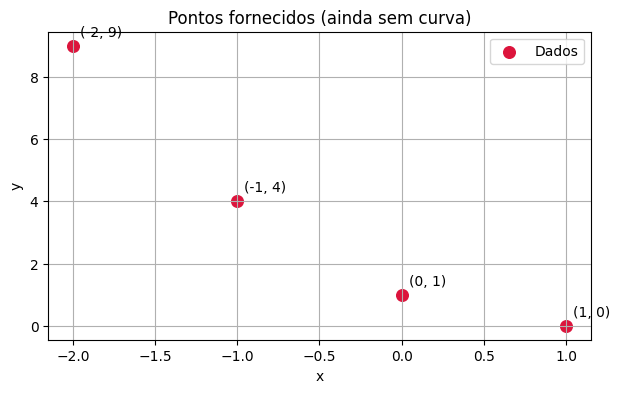

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

x = np.array([-2, -1, 0, 1], dtype=float)
y = np.array([9, 4, 1, 0], dtype=float)

plt.figure(figsize=(7, 4))
plt.scatter(x, y, color="crimson", s=70, label="Dados")
for xi, yi in zip(x, y):
    plt.annotate(f"({xi:g}, {yi:g})", (xi, yi), xytext=(5, 7), textcoords="offset points")
plt.xlabel("x"); plt.ylabel("y"); plt.title("Pontos fornecidos (ainda sem curva)")
plt.grid(True); plt.legend(); plt.show()

**Descrevam a tendência dos pontos.** A curva precisa ser reta? Há mais de uma curva que poderia passar pelos pontos?

## 4. Construindo o polinômio com uma ferramenta

Usaremos `numpy.polynomial.Polynomial.fit` para obter o polinômio de grau até $m-1$. O método faz o cálculo numericamente e depois convertemos para a forma usual em potências de $x$.

A expressão impressa pode conter coeficientes muito pequenos, como $10^{-14}$, que representam zero dentro da precisão numérica. Não confundam esses resíduos de arredondamento com termos relevantes.

In [ ]:
polinomio = np.polynomial.Polynomial.fit(x, y, deg=len(x)-1).convert()
print("Polinômio na forma usual:")
print(polinomio)
print("\nCoeficientes em ordem crescente (termo constante primeiro):")
print(polinomio.coef)

Polinômio na forma usual:
1.0 - 2.0·x + 1.0·x² + (7.43830132e-16)·x³

Coeficientes em ordem crescente (termo constante primeiro):
[ 1.00000000e+00 -2.00000000e+00  1.00000000e+00  7.43830132e-16]


### Interpretando a expressão

Na forma usual, um polinômio cúbico é escrito como $P(x)=a_0+a_1x+a_2x^2+a_3x^3$. O vetor de coeficientes retornado pelo NumPy segue essa ordem: constante, $x$, $x^2$, $x^3$.

**Registrem a expressão obtida e identifiquem seu grau.** Se algum coeficiente for praticamente zero, indiquem isso.

In [ ]:
# Conferência automática: comparar P(x_i) com cada y_i
valores_nos_nos = polinomio(x)
for xi, yi, pi in zip(x, y, valores_nos_nos):
    print(f"x={xi:5.1f} | dado={yi:10.6f} | P(x)={pi:10.6f} | diferença={abs(yi-pi):.2e}")

x= -2.0 | dado=  9.000000 | P(x)=  9.000000 | diferença=5.33e-15
x= -1.0 | dado=  4.000000 | P(x)=  4.000000 | diferença=1.78e-15
x=  0.0 | dado=  1.000000 | P(x)=  1.000000 | diferença=6.66e-16
x=  1.0 | dado=  0.000000 | P(x)=  0.000000 | diferença=2.44e-15


**Perguntas de interpretação**

1. As diferenças são zero ou muito pequenas?
2. O que essa conferência mostra sobre a curva nos nós?
3. O que ela **não** mostra sobre valores entre os nós ou fora do intervalo?

**Respostas:** `# SUA RESPOSTA`

## 5. Visualizar não é o mesmo que validar

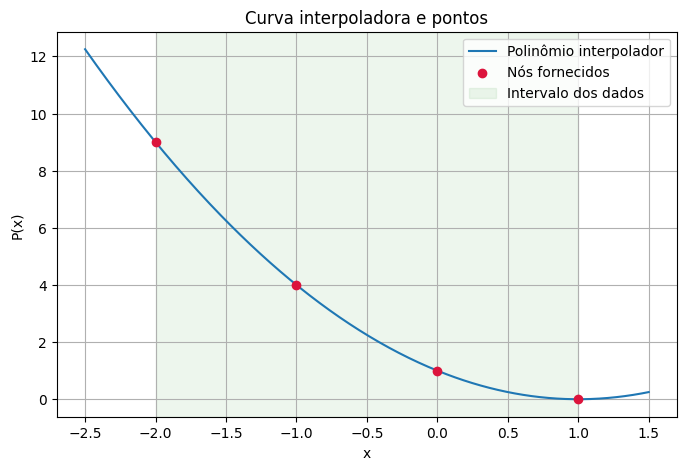

In [ ]:
xx = np.linspace(x.min()-0.5, x.max()+0.5, 400)
plt.figure(figsize=(8, 5))
plt.plot(xx, polinomio(xx), label="Polinômio interpolador")
plt.scatter(x, y, color="crimson", zorder=3, label="Nós fornecidos")
plt.axvspan(x.min(), x.max(), color="green", alpha=0.07, label="Intervalo dos dados")
plt.xlabel("x"); plt.ylabel("P(x)"); plt.title("Curva interpoladora e pontos")
plt.grid(True); plt.legend(); plt.show()

O gráfico ajuda a perceber a forma da curva, mas uma figura pode esconder diferenças pequenas ou induzir a confiar demais em uma região sem dados. A faixa sombreada é o intervalo de interpolação; fora dela estamos extrapolando.

**Descrevam:** a curva passa pelos pontos? O comportamento fora do intervalo parece sustentado pelos dados?

## 6. Calcular valores intermediários

Escolham valores que não aparecem na tabela. O resultado de $P(x)$ é uma estimativa interpolada quando $x$ está entre o menor e o maior nó.

In [ ]:
consultas = np.array([-1.5, -0.5, 0.5, 0.9, 2.0])
for q in consultas:
    tipo = "interpolação" if x.min() <= q <= x.max() else "extrapolação"
    print(f"P({q:4.1f}) = {polinomio(q): .6f}  ({tipo})")

P(-1.5) =  6.250000  (interpolação)
P(-0.5) =  2.250000  (interpolação)
P( 0.5) =  0.250000  (interpolação)
P( 0.9) =  0.010000  (interpolação)
P( 2.0) =  1.000000  (extrapolação)


**Tabela de registro**

| $x$ consultado | Estimativa $P(x)$ | Interpolação ou extrapolação? |

### Atividade: comparar ferramentas

Pesquisem pelo menos **duas** ferramentas além deste código (por exemplo GeoGebra, WolframAlpha, SageMath ou calculadora online). Insiram os mesmos pontos e comparem a expressão e os valores em $x=-1{,}5$ e $x=0{,}5$.

| Ferramenta e link | Como inseriram os dados? | Expressão/resultado | O que foi fácil ou difícil? |
|---|---|---|---|
| 1. | | | |
| 2. | | | |

Se os resultados diferirem, verifiquem se a ferramenta calculou interpolação polinomial, regressão, spline ou arredondou coeficientes. São operações diferentes.

## 7. Segundo conjunto: dados de medição

Agora considere uma sequência simplificada de medições. O valor de $x$ pode representar tempo, e $y$ uma grandeza observada.

1.2 + 1.11666667·x - 0.45·x² + 0.13333333·x³
Estimativa em x=1.5: 2.312500


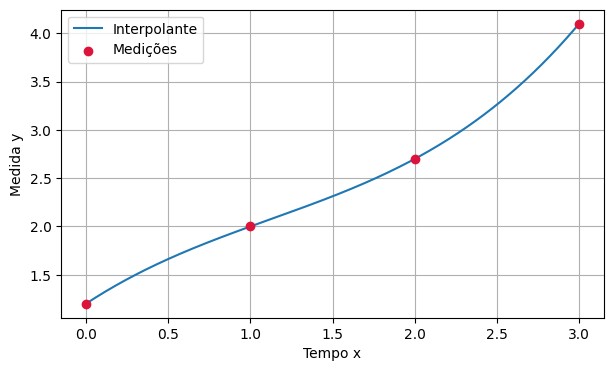

In [ ]:
xB = np.array([0, 1, 2, 3], dtype=float)
yB = np.array([1.2, 2.0, 2.7, 4.1], dtype=float)
pB = np.polynomial.Polynomial.fit(xB, yB, deg=len(xB)-1).convert()
print(pB)
print(f"Estimativa em x=1.5: {pB(1.5):.6f}")
xb_plot = np.linspace(xB.min(), xB.max(), 300)
plt.figure(figsize=(7,4)); plt.plot(xb_plot,pB(xb_plot),label="Interpolante")
plt.scatter(xB,yB,color="crimson",label="Medições",zorder=3)
plt.xlabel("Tempo x"); plt.ylabel("Medida y"); plt.grid(True); plt.legend(); plt.show()

**Discussão:** $x=1{,}5$ está entre nós? Qual a estimativa?


## 8. Experimento: alterar uma medição

Ajustem somente o valor medido em $x=2$ e observem o efeito na curva. Abaixo usamos uma alteração de $+0{,}5$; vocês podem testar outra.

Estimativa original em x=1.5: 2.312499999999999
Estimativa alterada em x=1.5: 2.59375


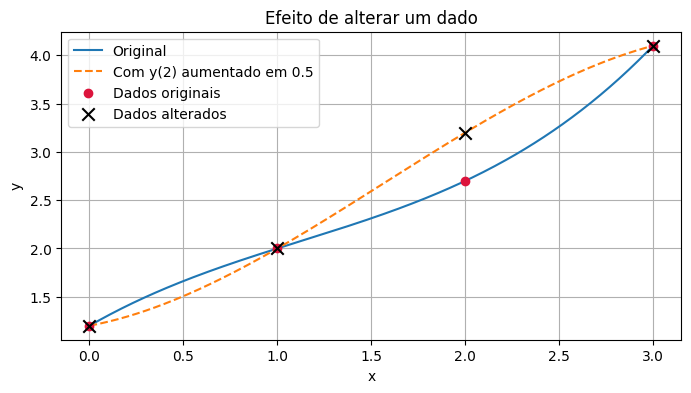

In [ ]:
yB_alterado = yB.copy()
yB_alterado[2] += 0.5
pB_alterado = np.polynomial.Polynomial.fit(xB, yB_alterado, deg=len(xB)-1).convert()
print("Estimativa original em x=1.5:", pB(1.5))
print("Estimativa alterada em x=1.5:", pB_alterado(1.5))
plt.figure(figsize=(8,4))
plt.plot(xb_plot,pB(xb_plot),label="Original")
plt.plot(xb_plot,pB_alterado(xb_plot),"--",label="Com y(2) aumentado em 0.5")
plt.scatter(xB,yB,color="crimson",zorder=3,label="Dados originais")
plt.scatter(xB,yB_alterado,marker="x",s=80,color="black",zorder=4,label="Dados alterados")
plt.grid(True); plt.legend(); plt.xlabel("x"); plt.ylabel("y"); plt.title("Efeito de alterar um dado"); plt.show()

**Registrem:** qual ponto foi alterado? O que aconteceu ao valor em $x=1{,}5$? A curva mudou apenas perto do ponto alterado? Por que pequenas incertezas de medição podem ser importantes?

## 9. Quando o grau alto pode ser um problema?

Com muitos pontos, o polinômio interpolador pode oscilar entre nós, especialmente quando os pontos estão igualmente espaçados. Essa oscilação é um fenômeno conhecido como **fenômeno de Runge** em certos exemplos. Mais pontos e ajuste exato não significam sempre uma curva mais adequada.

A atividade seguinte é uma demonstração visual: comparem uma função suave com polinômios que passam por quantidades crescentes de pontos igualmente espaçados.

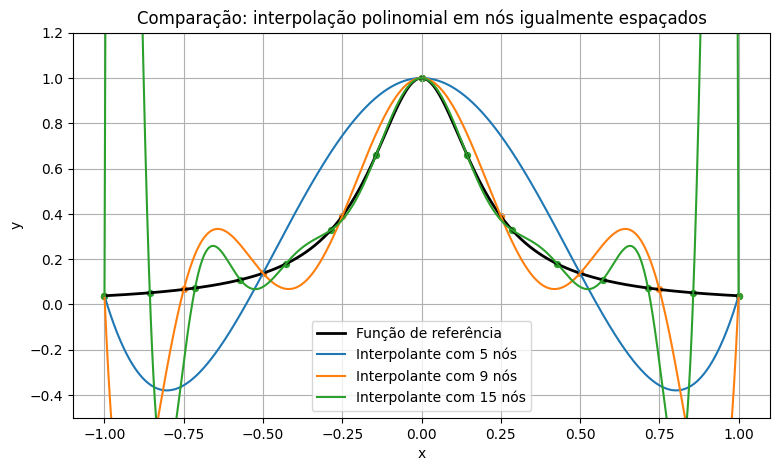

In [ ]:
def f(t):
    return 1/(1+25*t**2)

t_plot = np.linspace(-1,1,1000)
plt.figure(figsize=(9,5))
plt.plot(t_plot,f(t_plot),color="black",linewidth=2,label="Função de referência")
for n in [5, 9, 15]:
    tn=np.linspace(-1,1,n)
    pn=np.polynomial.Polynomial.fit(tn,f(tn),deg=n-1).convert()
    plt.plot(t_plot,pn(t_plot),label=f"Interpolante com {n} nós")
    plt.scatter(tn,f(tn),s=18)
plt.ylim(-0.5,1.2); plt.grid(True); plt.legend(); plt.title("Comparação: interpolação polinomial em nós igualmente espaçados")
plt.xlabel("x"); plt.ylabel("y"); plt.show()

**Observação guiada:**

- Todas as curvas interpoladoras passam pelos pontos utilizados?
- O que ocorre perto das extremidades quando aumenta o número de nós?
- Para muitos dados, que alternativas vocês investigariam (por exemplo, interpolação por partes/splines)?

O objetivo é observar, não memorizar uma regra universal: o comportamento depende dos dados, dos nós e do método.

## 10. Interpolação versus regressão

Na interpolação, a curva passa pelos pontos fornecidos. Na **regressão**, escolhemos um modelo que procura representar a tendência geral, sem exigir que passe por cada observação. A regressão pode ser mais apropriada quando há ruído de medição.

| Aspecto | Interpolação | Regressão |
|---|---|---|
| Passa por todos os dados? | Sim (no caso polinomial exato) | Em geral, não |
| Uso comum | Estimar entre dados conhecidos | Representar tendência com dados ruidosos |
| Risco | Oscilação ou extrapolação ruim | Modelo inadequado ou resíduos grandes |

**Expliquem com suas palavras por que a curva interpoladora do conjunto B não prova que as medições são exatas ou sem ruído.**

## 11. Síntese e entrega

Escrevam uma síntese de 6–10 linhas, incluindo:
1. o que significa interpolar e a diferença para extrapolar;
2. quais ferramentas foram testadas e se concordaram;
3. o que mudou quando um dado foi alterado;
4. uma limitação observada na interpolação polinomial;
5. em que situação prática usariam o método e que cautela teriam.

**Síntese do grupo:**


### Checklist
- [ ] Expliquei o papel dos nós e do polinômio interpolador.
- [ ] Conferi numericamente que o polinômio reproduz os dados.
- [ ] Calculei e classifiquei valores consultados como interpolação/extrapolação.
- [ ] Comparei duas ferramentas com os mesmos dados.
- [ ] Fiz o experimento de alteração de dado e registrei observações.
- [ ] Analisei o exemplo com muitos nós e discuti limitações.

